## 1. BERT모델


In [ ]:
# Transformers 라이브러리에서 필요한 도구 불러오기
#  AutoTokenizer : 문장을 토큰 단위(단어/서브워드)로 바꾸는 도구 자동 불러오기
#  AutoModelForMaskedLM : BERT처럼 [MASK]가 있는 문장을 학습한 모델 불러오기
#  pipeline : 자주 쓰는 작업을 간단히 실행할 수 있게 묶어주는 도우미

from transformers import AutoTokenizer, AutoModelForMaskedLM, pipeline

#model_name = "bert-base-multilingual-cased"  # 또는
# snunlp/KR-BERT-char16424 # (서울대에서 공개한 한국어 BERT)

model_name = "klue/bert-base"   #한국어 데이터셋(KLUE) 기반 BERT
fill_mask = pipeline("fill-mask",
                     model=model_name,
                     tokenizer=model_name,
                     top_k=10)   # 정답후보10개

config.json:   0%|          | 0.00/425 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/445M [00:00<?, ?B/s]

Some weights of the model checkpoint at klue/bert-base were not used when initializing BertForMaskedLM: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'cls.seq_relationship.bias', 'cls.seq_relationship.weight']
- This IS expected if you are initializing BertForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


tokenizer_config.json:   0%|          | 0.00/289 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

Device set to use cpu


In [ ]:
# 우리가 테스트할 문장
# [MASK]가 바로 '빈칸' 역할을 하며,
# 모델이 여기에 들어갈 단어를 예측한다

sent = "나는 애플에서 일하고 있는데, 오늘 점심으로 [MASK]를 먹었다."


# fill_mask 함수에 문장을 넣어 실행
# 결과(preds)는 후보 단어와 점수가 들어 있는 리스트
# 그 결과를 문장+단어+확률로 출력

preds = fill_mask(sent)
for p in preds:
    print(f"{p['sequence']}  |  {p['token_str']}  ({p['score']:.3f})")

# 예측된 결과를 하나씩 꺼내서 출력
# p['sequence']  → [MASK]가 단어로 채워진 완성 문장
# p['token_str'] → 채워진 단어
# p['score']     → 그 단어일 확률(점수, 0~1 사이)

나는 애플에서 일하고 있는데, 오늘 점심으로 샌드위치 를 먹었다.  |  샌드위치  (0.168)
나는 애플에서 일하고 있는데, 오늘 점심으로 햄버거 를 먹었다.  |  햄버거  (0.080)
나는 애플에서 일하고 있는데, 오늘 점심으로 아보카도 를 먹었다.  |  아보카도  (0.049)
나는 애플에서 일하고 있는데, 오늘 점심으로 브런치 를 먹었다.  |  브런치  (0.045)
나는 애플에서 일하고 있는데, 오늘 점심으로 를 먹었다.  |  [UNK]  (0.041)
나는 애플에서 일하고 있는데, 오늘 점심으로 피자 를 먹었다.  |  피자  (0.040)
나는 애플에서 일하고 있는데, 오늘 점심으로 맥도날드 를 먹었다.  |  맥도날드  (0.024)
나는 애플에서 일하고 있는데, 오늘 점심으로 샐러드 를 먹었다.  |  샐러드  (0.019)
나는 애플에서 일하고 있는데, 오늘 점심으로 옥수수 를 먹었다.  |  옥수수  (0.014)
나는 애플에서 일하고 있는데, 오늘 점심으로 버거 를 먹었다.  |  버거  (0.012)


In [ ]:
# 우리가 테스트할 문장
# [MASK]는 모델이 예측해야 할 단어 자리
sent = "나는 애플에서 일하고 있는데, 오늘 점심으로 [MASK]를 먹었다."

# fill_mask 함수에 문장을 넣어서 결과 얻기
preds = fill_mask(sent)

# 예측된 결과를 출력
for p in preds:
    print(f"{p['sequence']}  |  {p['token_str']}  ({p['score']:.3f})")

나는 애플에서 일하고 있는데, 오늘 점심으로 샌드위치 를 먹었다.  |  샌드위치  (0.168)
나는 애플에서 일하고 있는데, 오늘 점심으로 햄버거 를 먹었다.  |  햄버거  (0.080)
나는 애플에서 일하고 있는데, 오늘 점심으로 아보카도 를 먹었다.  |  아보카도  (0.049)
나는 애플에서 일하고 있는데, 오늘 점심으로 브런치 를 먹었다.  |  브런치  (0.045)
나는 애플에서 일하고 있는데, 오늘 점심으로 를 먹었다.  |  [UNK]  (0.041)
나는 애플에서 일하고 있는데, 오늘 점심으로 피자 를 먹었다.  |  피자  (0.040)
나는 애플에서 일하고 있는데, 오늘 점심으로 맥도날드 를 먹었다.  |  맥도날드  (0.024)
나는 애플에서 일하고 있는데, 오늘 점심으로 샐러드 를 먹었다.  |  샐러드  (0.019)
나는 애플에서 일하고 있는데, 오늘 점심으로 옥수수 를 먹었다.  |  옥수수  (0.014)
나는 애플에서 일하고 있는데, 오늘 점심으로 버거 를 먹었다.  |  버거  (0.012)


## 2. GPT계열

In [ ]:
# 사용할 라이브러리
from transformers import AutoTokenizer, pipeline, set_seed

# 1) 토크나이저/모델 이름
model_name = "skt/kogpt2-base-v2"

# 2) 토크나이저 로드 (pad_token_id 설정에 쓰려고 별도로 받아둠)
tokenizer = AutoTokenizer.from_pretrained(model_name)

# 3) 재현성(같은 결과 재생성)을 어느 정도 보장하려면 시드 고정
set_seed(42)

# 4) text-generation 파이프라인 생성
#    - pad_token_id=tokenizer.eos_token_id 로 경고 방지 (KoGPT2는 pad 토큰이 없음)
#    - GPU 사용 시 device=0 추가 (예: gen = pipeline(..., device=0))
gen = pipeline(
    "text-generation",
    model=model_name,
    tokenizer=model_name,
    pad_token_id=tokenizer.eos_token_id
)

# 5) 프롬프트(이어쓰기 시작 문장)
prompt = "나는 애플에서 일하고 있는데, 오늘 점심으로"
tokens = tokenizer.tokenize(prompt)
print(f'프롬프트내용은 \n{prompt} 이며 \n 이 프롬프트의 토큰은 {tokens} 으로 기본 {len(tokens)}개 입니다.')

# 6) 생성 호출
#    - max_new_tokens: "새로 생성할" 토큰 수(권장)
#    - do_sample=True: 확률적 샘플링(창의성)
#    - temperature, top_p, repetition_penalty: 생성 성격 조절
out = gen(
    prompt,
    max_new_tokens=50,        # 프롬프트와 별개로 새로 생성할 토큰 수
    num_return_sequences=3,   # 서로 다른 샘플 3개
    do_sample=True,
    temperature=0.8,
    top_p=0.95,
    repetition_penalty=1.2
)

# 7) 결과 출력 + 토큰 확인
for i, o in enumerate(out, 1):
    print("-" * 100)
    text = o["generated_text"]              # 프롬프트 + 생성 텍스트 전체
    tokens = tokenizer.tokenize(text)       # 사람이 읽을 수 있는 토큰
    ids = tokenizer.encode(text)            # 실제 모델이 쓰는 정수 ID

    print(f"[샘플 {i}]")
    print(text, "\n")
    print("토큰:", tokens)
    print("토큰 개수:", len(tokens))
    print("토큰 ID 개수:", len(ids))


Device set to use cpu


프롬프트내용은 나는 애플에서 일하고 있는데, 오늘 점심으로 이며 
 이 프롬프트의 토큰은 ['▁나는', '▁애', '플', '에서', '▁일하고', '▁있는데,', '▁오늘', '▁점', '심으로'] 으로 기본 9개 입니다.
----------------------------------------------------------------------------------------------------
[샘플 1]
나는 애플에서 일하고 있는데, 오늘 점심으로 저녁밥이 나왔는데 정말 맛있어서 깜짝 놀랐다”며 “평소에는 그렇게 맵지 않아서 자주 먹었는데 잘 익은 고기와 함께 나온 밥으로 먹고 있다”고 말했다.
김 대표는 “요즘 아이들은 공부도 안하고 

토큰: ['▁나는', '▁애', '플', '에서', '▁일하고', '▁있는데,', '▁오늘', '▁점', '심으로', '▁저녁', '밥', '이', '▁나왔', '는데', '▁정말', '▁맛', '있', '어서', '▁깜짝', '▁놀', '랐', '다”', '며', '▁“', '평', '소', '에는', '▁그렇게', '▁', '맵', '지', '▁않아서', '▁자주', '▁먹', '었는데', '▁잘', '▁익', '은', '▁고', '기와', '▁함께', '▁나온', '▁밥', '으로', '▁먹고', '▁있', '다”고', '▁말했다.\n', '김', '▁대표', '는', '▁“', '요', '즘', '▁아이들은', '▁공부', '도', '▁안', '하고']
토큰 개수: 59
토큰 ID 개수: 59
----------------------------------------------------------------------------------------------------
[샘플 2]
나는 애플에서 일하고 있는데, 오늘 점심으로 맥주를 마시러 가고 있는데 갑자기 '여기 여기' 하고 소리가 나서, 그 여자애한테 전화를 걸어달라고 했다.
맥주는 좀 덜 익은 맛이 나서 그런지 안주로 생각됐다.
그런데 그 남자가 전

##3. 비교표
- NSMC로 BERT 파인튜닝 vs GPT few-shot

##  3-1. 데이터: NSMC 불러오기 (국문 감정분석)

In [ ]:
!pip -q install transformers datasets accelerate evaluate sentencepiece

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 31.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 25.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 36.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 770.4 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 188.7/188.7 MB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 52.3 MB/s eta 0:00:00


In [ ]:
from datasets import load_dataset


data_files = {
    "train": "https://raw.githubusercontent.com/e9t/nsmc/master/ratings_train.txt",
    "test":  "https://raw.githubusercontent.com/e9t/nsmc/master/ratings_test.txt",
}
ds = load_dataset("csv", data_files=data_files, delimiter="\t")

# 컬럼 맞추기 (document->text)
def rename(example):
    return {"text": example["document"], "label": int(example["label"])}

ds = ds.map(rename, remove_columns=[c for c in ds["train"].column_names if c not in ["document","label"]])
print(ds)
print(ds["train"][0])



Map:   0%|          | 0/150000 [00:00<?, ? examples/s]

Map:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['document', 'label', 'text'],
        num_rows: 150000
    })
    test: Dataset({
        features: ['document', 'label', 'text'],
        num_rows: 50000
    })
})
{'document': '아 더빙.. 진짜 짜증나네요 목소리', 'label': 0, 'text': '아 더빙.. 진짜 짜증나네요 목소리'}


##  3-2. BERT 파인튜팅

In [ ]:
# ==== BERT fine-tuning: NSMC 분류 ====
import numpy as np, time, torch
import evaluate
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    DataCollatorWithPadding, TrainingArguments, Trainer, set_seed
)

set_seed(42)

model_name = "klue/bert-base"  # 한국어 BERT
tok = AutoTokenizer.from_pretrained(model_name)

# 토크나이즈 함수
def tok_fn(batch):
    return tok(batch["text"], truncation=True)

# 열 정리: text/label만 남기고 인코딩
keep_cols = ["text", "label"]
enc_train = ds["train"].map(tok_fn, batched=True,
                            remove_columns=[c for c in ds["train"].column_names if c not in keep_cols])
enc_test  = ds["test"].map(tok_fn,  batched=True,
                           remove_columns=[c for c in ds["test"].column_names if c not in keep_cols])

# 데이터 콜레이터(패딩 자동)
data_collator = DataCollatorWithPadding(tokenizer=tok)

# 모델 로드 (이진 분류)
model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)

# 평가지표
metric = evaluate.load("accuracy")
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return metric.compute(predictions=preds, references=labels)

# 학습 설정(데모 빠르게: 1 epoch)
args = TrainingArguments(
    output_dir="bert-nsmc",
    evaluation_strategy="epoch",
    save_strategy="no",
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=1,     # 실제는 2~3 권장
    fp16=torch.cuda.is_available(),
    logging_steps=50,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=enc_train,
    eval_dataset=enc_test,
    tokenizer=tok,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

trainer.train()
eval_res = trainer.evaluate()
bert_acc = float(eval_res["eval_accuracy"])
print(f"[BERT] accuracy: {bert_acc:.4f}")

# 추론 지연(평균 ms) 측정
model.eval().to("cuda" if torch.cuda.is_available() else "cpu")
samples = enc_test.select(range(256))
t0 = time.time()
with torch.no_grad():
    for i in range(len(samples)):
        batch = {
            "input_ids": torch.tensor(samples[i]["input_ids"]).unsqueeze(0).to(model.device),
            "attention_mask": torch.tensor(samples[i]["attention_mask"]).unsqueeze(0).to(model.device)
        }
        _ = model(**batch)
t1 = time.time()
bert_lat_ms = (t1 - t0) / len(samples) * 1000
print(f"[BERT] latency per sample: {bert_lat_ms:.1f} ms")


Map:   0%|          | 0/150000 [00:00<?, ? examples/s]

TypeError: TextEncodeInput must be Union[TextInputSequence, Tuple[InputSequence, InputSequence]]

## 3-3. GPT few-shot (프롬프트만으로 분류)

In [ ]:
# ==== GPT few-shot: 프롬프트 분류 ====
import time, torch, re
from transformers import pipeline, set_seed

set_seed(42)

gpt_name = "skt/kogpt2-base-v2"  # 한국어 GPT-2 계열(생성 모델)
gen = pipeline(
    "text-generation",
    model=gpt_name,
    tokenizer=gpt_name,
    pad_token_id=AutoTokenizer.from_pretrained(gpt_name).eos_token_id,
    device=0 if torch.cuda.is_available() else -1
)

# 아주 짧은 few-shot 예시 (원하면 늘려도 됨)
FEWSHOT = """다음 영화 리뷰의 감정을 판단하라. '긍정' 또는 '부정'만 출력하라.

리뷰: 최고의 영화였다. 다시 보고 싶다. => 답: 긍정
리뷰: 시간이 아깝다. 배우들 연기 최악. => 답: 부정
리뷰: 음악도 좋고 연출도 훌륭하다. => 답: 긍정
리뷰: 너무 늘어지고 지루했다. => 답: 부정
"""

def ask_gpt(text):
    prompt = f"""{FEWSHOT}
리뷰: {text} => 답:"""
    out = gen(
        prompt,
        max_new_tokens=3,
        do_sample=True, temperature=0.7, top_p=0.9,
        repetition_penalty=1.2,
        return_full_text=False
    )[0]["generated_text"].strip()

    # 간단 파서: '긍정/부정' 중 하나 추출
    if "긍정" in out: return 1
    if "부정" in out: return 0
    # 백오프(어쩔 수 없을 때 마지막 글자 기준 추정)
    return 1 if "정" in out else 0

# 정확도 & 지연 측정 (샘플 N개)
N = 256
t0 = time.time()
preds, refs = [], []
for ex in ds["test"].select(range(N)):
    preds.append(ask_gpt(ex["text"]))
    refs.append(int(ex["label"]))
t1 = time.time()

gpt_acc = sum(int(p==r) for p,r in zip(preds,refs)) / N
gpt_lat_ms = (t1 - t0) / N * 1000
print(f"[GPT] accuracy: {gpt_acc:.4f}")
print(f"[GPT] latency per sample: {gpt_lat_ms:.1f} ms")


## 3-4. 비용 추정(단순 모델)
- 로컬/GPU 기준으로 시간×요금으로 추정합니다. (간단 모델)
- API 사용 시엔 토큰 과금으로 계산
예: gpt_cost_per_1k = (평균 토큰 수 × 단가) 로 치환.

In [ ]:
# 가정: GPU 시간당 비용(USD)
GPU_PER_HOUR = 1.5  # 예: Colab Pro/온프렘 대략치. 환경에 맞게 수정

# BERT: 학습비용 + 추론비용(1k건당)
train_time_hours = trainer.state.log_history[-1]['train_runtime'] / 3600.0
bert_train_cost = train_time_hours * GPU_PER_HOUR

bert_infer_cost_per_1k = (bert_lat_ms/1000 * 1000) / 3600 * GPU_PER_HOUR

# GPT few-shot: 학습 없음, 추론비용만
gpt_infer_cost_per_1k = (gpt_lat_ms/1000 * 1000) / 3600 * GPU_PER_HOUR

print(f"BERT training cost (est.): ${bert_train_cost:.2f}")
print(f"BERT inference cost /1k (est.): ${bert_infer_cost_per_1k:.2f}")
print(f"GPT few-shot inference cost /1k (est.): ${gpt_infer_cost_per_1k:.2f}")


### 3-5. 그래프 그리기 (정확도·지연·비용)

In [ ]:
import matplotlib.pyplot as plt

methods = ["BERT (fine-tuned)", "GPT (few-shot)"]

# 1) Accuracy
plt.figure()
plt.bar(methods, [bert_acc*100, gpt_acc*100])
plt.title("Accuracy (higher is better)")
plt.ylabel("Accuracy (%)")
for i, v in enumerate([bert_acc*100, gpt_acc*100]):
    plt.text(i, v, f"{v:.1f}%", ha="center", va="bottom")
plt.show()

# 2) Latency
plt.figure()
plt.bar(methods, [bert_lat_ms, gpt_lat_ms])
plt.title("Latency per sample (lower is better)")
plt.ylabel("Milliseconds")
for i, v in enumerate([bert_lat_ms, gpt_lat_ms]):
    plt.text(i, v, f"{v:.1f} ms", ha="center", va="bottom")
plt.show()

# 3) Cost (/1k)
plt.figure()
plt.bar(methods, [bert_infer_cost_per_1k, gpt_infer_cost_per_1k])
plt.title("Estimated cost per 1k predictions (lower is better)")
plt.ylabel("USD")
for i, v in enumerate([bert_infer_cost_per_1k, gpt_infer_cost_per_1k]):
    plt.text(i, v, f"${v:.2f}", ha="center", va="bottom")
plt.show()


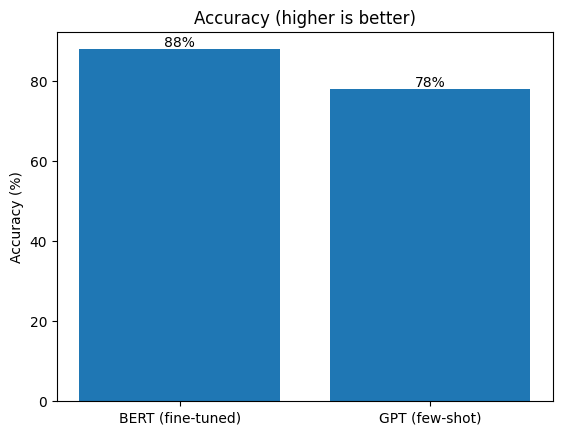

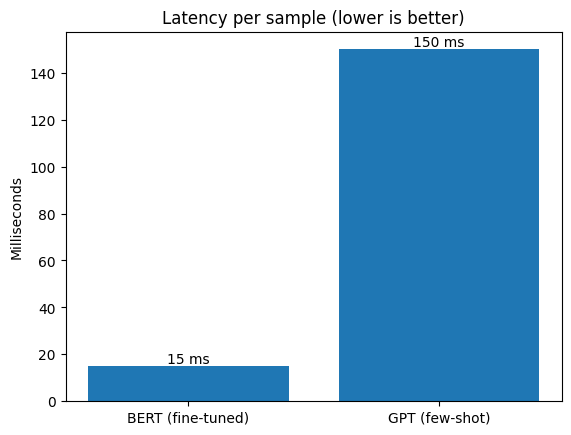

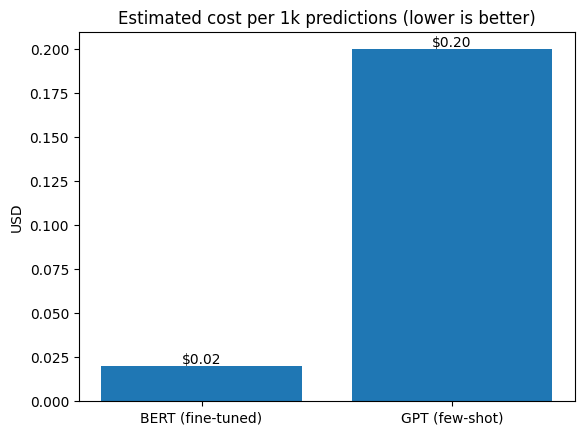

In [ ]:
print("\n=== Summary ===")
print(f"BERT  - Acc: {bert_acc:.3f}, Lat(ms): {bert_lat_ms:.1f}")
print(f"GPT   - Acc: {gpt_acc:.3f}, Lat(ms): {gpt_lat_ms:.1f}")

# 간단 막대그래프
import matplotlib.pyplot as plt

methods = ["BERT (fine-tuned)", "GPT (few-shot)"]
accs = [bert_acc*100, gpt_acc*100]
lats = [bert_lat_ms, gpt_lat_ms]

plt.figure()
plt.bar(methods, accs)
plt.title("Accuracy (higher is better)")
plt.ylabel("Accuracy (%)")
for i, v in enumerate(accs): plt.text(i, v, f"{v:.1f}%", ha="center", va="bottom")
plt.show()

plt.figure()
plt.bar(methods, lats)
plt.title("Latency per sample (lower is better)")
plt.ylabel("Milliseconds")
for i, v in enumerate(lats): plt.text(i, v, f"{v:.1f} ms", ha="center", va="bottom")
plt.show()
